In [74]:
import duckdb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import os
import datetime as dt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
from matplotlib.ticker import MaxNLocator
from IPython.display import display
from ydata_profiling import ProfileReport
from scipy import stats
from statsmodels.stats.power import FTestAnovaPower
from sklearn.calibration import calibration_curve
from scipy.stats import chi2_contingency
from scipy.optimize import brentq
%matplotlib inline
import dataframe_image as dfi



In [5]:
con = duckdb.connect(r"C:/Users/jacob/ma_quality/ma_quality.duckdb")

In [6]:
years = [2022, 2023, 2024, 2025, 2026]
train_years = [2022, 2023, 2024]
valid_year = 2025
predict_year = 2026

## Build Train, Test, Predict DataFrames 

#### KED

In [7]:
ked_blocks = []


for year in years:
    may = con.execute(f"""
        SELECT patient AS patient_id, {year} AS year, in_numerator::INT AS closed_may
        FROM ked(DATE '{year}-01-01', DATE '{year}-05-15')
    """).df()

    yend = con.execute(f"""
        SELECT patient AS patient_id, {year} AS year, in_numerator::INT AS closed_eoy
        FROM ked(DATE '{year}-01-01', DATE '{year}-12-31')
    """).df()

    block = (may.merge(yend, on=["patient_id", "year"], how="inner"))
    ked_blocks.append(block)

ked_pop = pd.concat(ked_blocks, ignore_index=True)
ked_pop.head()


,patient_id,year,closed_may,closed_eoy
0,3f953d4e-ddbf-5306-729e-5ff58d1247b7,2022,1,1
1,9640e482-b931-6c43-c9af-3d7077d6b59f,2022,1,1
2,42d8f907-119b-b8a2-a773-b8b042e8420c,2022,1,1
3,2fb3abcb-72b9-d8ed-4f45-279691b574fb,2022,1,1
4,b96e73cc-c51b-95f8-ccab-c797a03cd2c0,2022,1,1


In [8]:
lab_blocks = []

for year in years:
    labs = con.execute(f"""
          SELECT patient AS patient_id,
                 {year} AS year,
                MAX(CASE WHEN code='33914-3' THEN 1 ELSE 0 END) AS has_egfr,
                MAX(CASE WHEN code='14959-1' THEN 1 ELSE 0 END) AS has_uacr
          FROM observations
          WHERE code IN ('33914-3','14959-1')
            AND date BETWEEN DATE '{year}-01-01' AND DATE '{year}-05-15'
            AND patient IN (SELECT patient FROM ked(DATE '{year}-01-01', DATE '{year}-05-15'))  
          GROUP BY patient
      """).df()
    lab_blocks.append(labs)

all_labs = pd.concat(lab_blocks ,ignore_index = True)

ked_pop = ked_pop.merge(all_labs, on=['patient_id', 'year'], how='left')
ked_pop['has_egfr'] = ked_pop['has_egfr'].fillna(0).astype(int)
ked_pop['has_uacr'] = ked_pop['has_uacr'].fillna(0).astype(int)

ked_pop.head()

,patient_id,year,closed_may,closed_eoy,has_egfr,has_uacr
0,3f953d4e-ddbf-5306-729e-5ff58d1247b7,2022,1,1,1,1
1,9640e482-b931-6c43-c9af-3d7077d6b59f,2022,1,1,1,1
2,42d8f907-119b-b8a2-a773-b8b042e8420c,2022,1,1,1,1
3,2fb3abcb-72b9-d8ed-4f45-279691b574fb,2022,1,1,1,1
4,b96e73cc-c51b-95f8-ccab-c797a03cd2c0,2022,1,1,1,1


In [9]:
prior_blocks = []

for year in years:
    prior = con.execute(f"""
        SELECT patient AS patient_id, {year} AS year, in_numerator::INT AS closed_ked_prioryr
        FROM ked(DATE '{year - 1}-01-01', DATE '{year - 1}-12-31')
    """).df()
    prior_blocks.append(prior)
all_priors = pd.concat(prior_blocks, ignore_index=True)
ked_pop = ked_pop.merge(all_priors, on=['patient_id', 'year'], how='left')
ked_pop['closed_ked_prioryr'] = ked_pop['closed_ked_prioryr'].fillna(0).astype(int)
ked_pop.head()

,patient_id,year,closed_may,closed_eoy,has_egfr,has_uacr,closed_ked_prioryr
0,3f953d4e-ddbf-5306-729e-5ff58d1247b7,2022,1,1,1,1,1
1,9640e482-b931-6c43-c9af-3d7077d6b59f,2022,1,1,1,1,0
2,42d8f907-119b-b8a2-a773-b8b042e8420c,2022,1,1,1,1,1
3,2fb3abcb-72b9-d8ed-4f45-279691b574fb,2022,1,1,1,1,1
4,b96e73cc-c51b-95f8-ccab-c797a03cd2c0,2022,1,1,1,1,1


In [10]:
enc_blocks_ked = []

for year in years:
    enc_ked = con.execute(f"""
        WITH ytd_enc AS (
            SELECT patient AS patient_id, COUNT(*) AS enc_ytd
            FROM encounters
            WHERE start_date BETWEEN DATE '{year}-01-01' AND DATE '{year}-05-15'
            GROUP BY patient
        ),
        prior_enc AS (
            SELECT patient AS patient_id, COUNT(*) AS enc_prior
            FROM encounters
            WHERE start_date BETWEEN DATE '{year - 1}-01-01' AND DATE '{year - 1}-12-31'
            GROUP BY patient
        ),
        comorb AS (
            SELECT patient AS patient_id, COUNT(DISTINCT code) AS n_comorb
            FROM conditions
            WHERE start_date <= DATE '{year}-05-15'
            GROUP BY patient
        )
        SELECT
            p.id AS patient_id,
            {year} AS year,
            COALESCE(y.enc_ytd, 0)::DOUBLE   / GREATEST(COALESCE(c.n_comorb, 0), 1) AS encounters_ytd_comorbidities,
            COALESCE(pr.enc_prior, 0)::DOUBLE / GREATEST(COALESCE(c.n_comorb, 0), 1) AS encounters_prioryr_comorbidities
        FROM population p
        LEFT JOIN ytd_enc   y  ON y.patient_id  = p.id
        LEFT JOIN prior_enc pr ON pr.patient_id = p.id
        LEFT JOIN comorb    c  ON c.patient_id  = p.id
    """).df()
    enc_blocks_ked.append(enc_ked)

all_enc_ked = pd.concat(enc_blocks_ked, ignore_index=True)
ked_pop = ked_pop.merge(all_enc_ked, on=['patient_id', 'year'], how='left')
ked_pop.head()

,patient_id,year,closed_may,closed_eoy,has_egfr,has_uacr,closed_ked_prioryr,encounters_ytd_comorbidities,encounters_prioryr_comorbidities
0,3f953d4e-ddbf-5306-729e-5ff58d1247b7,2022,1,1,1,1,1,0.317073,0.731707
1,9640e482-b931-6c43-c9af-3d7077d6b59f,2022,1,1,1,1,0,0.055556,0.083333
2,42d8f907-119b-b8a2-a773-b8b042e8420c,2022,1,1,1,1,1,0.187500,0.645833
3,2fb3abcb-72b9-d8ed-4f45-279691b574fb,2022,1,1,1,1,1,0.085714,0.314286
4,b96e73cc-c51b-95f8-ccab-c797a03cd2c0,2022,1,1,1,1,1,0.085714,0.257143


In [11]:
new_blocks = []

for year in years:
    new = con.execute(f"""
        WITH prior_pop AS (
            SELECT DISTINCT patient AS patient_id
            FROM ked(DATE '{year - 1}-01-01', DATE '{year - 1}-12-31')
        )
        SELECT
            p.id AS patient_id,
            {year} AS year,
            CASE WHEN pp.patient_id IS NULL THEN 1 ELSE 0 END AS new_member
        FROM population p
        LEFT JOIN prior_pop pp ON pp.patient_id = p.id
    """).df()
    new_blocks.append(new)

all_new = pd.concat(new_blocks, ignore_index=True)
ked_pop = ked_pop.merge(all_new, on=['patient_id', 'year'], how='left')
ked_pop['new_member'] = ked_pop['new_member'].fillna(0).astype(int)
ked_pop.head()

,patient_id,year,closed_may,closed_eoy,has_egfr,has_uacr,closed_ked_prioryr,encounters_ytd_comorbidities,encounters_prioryr_comorbidities,new_member
0,3f953d4e-ddbf-5306-729e-5ff58d1247b7,2022,1,1,1,1,1,0.317073,0.731707,0
1,9640e482-b931-6c43-c9af-3d7077d6b59f,2022,1,1,1,1,0,0.055556,0.083333,0
2,42d8f907-119b-b8a2-a773-b8b042e8420c,2022,1,1,1,1,1,0.187500,0.645833,0
3,2fb3abcb-72b9-d8ed-4f45-279691b574fb,2022,1,1,1,1,1,0.085714,0.314286,0
4,b96e73cc-c51b-95f8-ccab-c797a03cd2c0,2022,1,1,1,1,1,0.085714,0.257143,0


In [12]:
ked_train = ked_pop[ked_pop["year"].isin(train_years)].copy()
ked_valid = ked_pop[ked_pop["year"] == valid_year].copy()
ked_predict = ked_pop[ked_pop["year"] == predict_year].copy()

#### CBP

In [13]:
cbp_blocks = []

for year in years:
    may = con.execute(f"""
        SELECT patient AS patient_id, {year} AS year, in_numerator::INT AS closed_may
        FROM cbp(DATE '{year}-01-01', DATE '{year}-05-15')
    """).df()

    yend = con.execute(f"""
        SELECT patient AS patient_id, {year} AS year, in_numerator::INT AS closed_eoy
        FROM cbp(DATE '{year}-01-01', DATE '{year}-12-31')
    """).df()

    block = (may.merge(yend, on=["patient_id", "year"], how="inner"))
    cbp_blocks.append(block)

cbp_pop = pd.concat(cbp_blocks, ignore_index=True)
cbp_pop.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,patient_id,year,closed_may,closed_eoy
0,d7aa4643-ba19-c0cd-06b4-d93759e37f31,2022,1,1
1,4c4ed904-2545-90a2-fb05-63e1b6ddab22,2022,1,1
2,48941da2-fcf1-0469-1bef-148d6befaa1e,2022,1,1
3,022acce5-3060-d4ba-3c69-c458a17d430f,2022,0,0
4,13900c8f-9d2c-0e7d-b5ce-82fa910981dc,2022,1,1


In [14]:
last_readings = []

for year in years:
    block = con.execute(f"""
        WITH daily AS (                              
            SELECT o.patient AS patient_id,
                   o.date::DATE AS reading_date,
                   MIN(CASE WHEN o.code = '8480-6' THEN o.value::DOUBLE END) AS systolic,  
                   MIN(CASE WHEN o.code = '8462-4' THEN o.value::DOUBLE END) AS diastolic
            FROM observations o
            JOIN encounters e ON e.id = o.encounter
            WHERE o.code IN ('8480-6', '8462-4')
              AND e.encounterclass NOT IN ('inpatient', 'emergency')     
              AND o.date BETWEEN DATE '{year}-01-01' AND DATE '{year}-05-15'
            GROUP BY o.patient, o.date::DATE
        ),
        latest AS (
            SELECT *, row_number() OVER (PARTITION BY patient_id ORDER BY reading_date DESC) AS rn
            FROM daily
            WHERE systolic IS NOT NULL AND diastolic IS NOT NULL         
        ),
        history AS (
            SELECT patient_id,
                   MAX(CASE WHEN systolic >= 140 OR diastolic >= 90 THEN 1 ELSE 0 END) AS any_uncontrolled_ytd
            FROM daily
            WHERE systolic IS NOT NULL AND diastolic IS NOT NULL
            GROUP BY patient_id
        ),
        staged AS (                                                       
            SELECT patient_id,
                   reading_date,
                   CASE WHEN systolic >= 180 OR diastolic >= 110 THEN '180_plus'
                        WHEN systolic >= 160 OR diastolic >= 100 THEN '160_179'
                        WHEN systolic >= 150 OR diastolic >= 95  THEN '150_159'
                        WHEN systolic >= 140 OR diastolic >= 90  THEN '140_149'
                        WHEN systolic >= 130 OR diastolic >= 85  THEN '130_139'
                        WHEN systolic >= 120 OR diastolic >= 80  THEN '120_129'
                        WHEN systolic >= 110 OR diastolic >= 75  THEN '110_119'
                        ELSE 'under_110'
                   END AS stage
            FROM latest
            WHERE rn = 1
        )
        SELECT s.patient_id,
               {year} AS year,
               (s.stage = '140_149')::INT  AS bp_140_149,
               (s.stage = '150_159')::INT  AS bp_150_159,
               (s.stage = '160_179')::INT  AS bp_160_179,
               (s.stage = '180_plus')::INT AS bp_180_plus,
               (s.stage = '130_139')::INT  AS bp_130_139,
               (s.stage = '120_129')::INT  AS bp_120_129,
               (s.stage = '110_119')::INT  AS bp_110_119,
               date_diff('day', s.reading_date, DATE '{year}-05-15') AS days_since_last,
               h.any_uncontrolled_ytd
        FROM staged s
        LEFT JOIN history h ON h.patient_id = s.patient_id
    """).df()
    last_readings.append(block)

band_cols = ["bp_140_149", "bp_150_159", "bp_160_179", "bp_180_plus"]
under_band_cols = ["bp_130_139", "bp_120_129", "bp_110_119"]
all_last_readings = pd.concat(last_readings, ignore_index=True)
cbp_pop = cbp_pop.merge(all_last_readings, on=["patient_id", "year"], how="left")
cbp_pop[band_cols + under_band_cols] = cbp_pop[band_cols + under_band_cols].fillna(0).astype(int)
cbp_pop["any_uncontrolled_ytd"] = cbp_pop["any_uncontrolled_ytd"].fillna(0).astype(int)
cbp_pop.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,patient_id,year,closed_may,closed_eoy,bp_140_149,bp_150_159,bp_160_179,bp_180_plus,bp_130_139,bp_120_129,bp_110_119,days_since_last,any_uncontrolled_ytd
0,d7aa4643-ba19-c0cd-06b4-d93759e37f31,2022,1,1,0,0,0,0,0,1,0,5.0,0
1,4c4ed904-2545-90a2-fb05-63e1b6ddab22,2022,1,1,0,0,0,0,0,1,0,17.0,0
2,48941da2-fcf1-0469-1bef-148d6befaa1e,2022,1,1,0,0,0,0,0,0,1,23.0,0
3,022acce5-3060-d4ba-3c69-c458a17d430f,2022,0,0,1,0,0,0,0,0,0,9.0,1
4,13900c8f-9d2c-0e7d-b5ce-82fa910981dc,2022,1,1,0,0,0,0,0,0,0,11.0,0


Average blood pressure reduction for one drug at standard dose was 9.1 mm Hg systolic and 5.5 mm Hg diastolic in this study: https://pubmed.ncbi.nlm.nih.gov/12829555/ . Bands are created in accordance to number of reductions to become controlled. The more severe of the systolic and diastolic readings determined which band the patient was put in. 

In [15]:
order = ["no_reading"] + band_cols
labeled = [y for y in years if y != predict_year]

open_rows = cbp_pop[(cbp_pop["closed_may"] == 0) & (cbp_pop["year"].isin(labeled))].copy()
open_rows["segment"] = (open_rows[band_cols].idxmax(axis=1)
                        .where(open_rows[band_cols].sum(axis=1) == 1, "no_reading"))

per_year = (open_rows.groupby(["year", "segment"])["closed_eoy"]
            .agg(members="size", closures="sum")
            .reindex(pd.MultiIndex.from_product([labeled, order], names=["year", "segment"])))
per_year["non_closures"] = per_year["members"] - per_year["closures"]

print(per_year.to_string())

                  members  closures  non_closures
year segment                                     
2022 no_reading      5370      4143          1227
     bp_140_149       606       124           482
     bp_150_159       379        18           361
     bp_160_179       300         8           292
     bp_180_plus       35         1            34
2023 no_reading      5667      4404          1263
     bp_140_149       675       159           516
     bp_150_159       392        20           372
     bp_160_179       297         7           290
     bp_180_plus       34         2            32
2024 no_reading      5924      4640          1284
     bp_140_149       681       132           549
     bp_150_159       385        16           369
     bp_160_179       322         8           314
     bp_180_plus       38         0            38
2025 no_reading      6290      4880          1410
     bp_140_149       704       143           561
     bp_150_159       386        15           371


bp_180_plus is far too thin recording 3 total closures between the years 2022-2025 so it will be merged with bp_160_179 renaming the column 160+.

In [16]:
cbp_pop["bp_160_plus"] = cbp_pop["bp_160_179"] + cbp_pop["bp_180_plus"]
cbp_pop = cbp_pop.drop(columns=["bp_160_179", "bp_180_plus"])
band_cols = ["bp_140_149", "bp_150_159", "bp_160_plus"]

In [17]:
order = ["no_reading"] + band_cols
labeled = [y for y in years if y != predict_year]

open_rows = cbp_pop[(cbp_pop["closed_may"] == 0) & (cbp_pop["year"].isin(labeled))].copy()
open_rows["segment"] = (open_rows[band_cols].idxmax(axis=1)
                        .where(open_rows[band_cols].sum(axis=1) == 1, "no_reading"))

per_year = (open_rows.groupby(["year", "segment"])["closed_eoy"]
            .agg(members="size", closures="sum")
            .reindex(pd.MultiIndex.from_product([labeled, order], names=["year", "segment"])))
per_year["non_closures"] = per_year["members"] - per_year["closures"]

print(per_year.to_string())

                  members  closures  non_closures
year segment                                     
2022 no_reading      5370      4143          1227
     bp_140_149       606       124           482
     bp_150_159       379        18           361
     bp_160_plus      335         9           326
2023 no_reading      5667      4404          1263
     bp_140_149       675       159           516
     bp_150_159       392        20           372
     bp_160_plus      331         9           322
2024 no_reading      5924      4640          1284
     bp_140_149       681       132           549
     bp_150_159       385        16           369
     bp_160_plus      360         8           352
2025 no_reading      6290      4880          1410
     bp_140_149       704       143           561
     bp_150_159       386        15           371
     bp_160_plus      361         5           356


In [18]:
closed_rows = cbp_pop[(cbp_pop["closed_may"] == 1) & (cbp_pop["year"].isin(labeled))].copy()
closed_rows["reopened"] = 1 - closed_rows["closed_eoy"]
closed_rows["segment"] = (closed_rows[under_band_cols].idxmax(axis=1)
                          .where(closed_rows[under_band_cols].sum(axis=1) == 1, "bp_under_110"))

per_year_closed = (closed_rows.groupby(["year", "segment"])["reopened"]
                   .agg(members="size", reopens="sum")
                   .reindex(pd.MultiIndex.from_product([labeled, ["bp_under_110"] + under_band_cols],
                                                       names=["year", "segment"])))
per_year_closed["retained"] = per_year_closed["members"] - per_year_closed["reopens"]
print(per_year_closed.to_string())

                   members  reopens  retained
year segment                                 
2022 bp_under_110     1549        0      1549
     bp_130_139        902      105       797
     bp_120_129       1200       16      1184
     bp_110_119       1169        2      1167
2023 bp_under_110     1748        0      1748
     bp_130_139        957       96       861
     bp_120_129       1229       14      1215
     bp_110_119       1237        0      1237
2024 bp_under_110     1878        0      1878
     bp_130_139       1048      119       929
     bp_120_129       1366       18      1348
     bp_110_119       1341        2      1339
2025 bp_under_110     2089        0      2089
     bp_130_139       1078      124       954
     bp_120_129       1435       19      1416
     bp_110_119       1377        1      1376


In [19]:
cbp_pop = cbp_pop.drop(columns=["bp_110_119"])
under_band_cols = ["bp_130_139", "bp_120_129"]

closed_rows = cbp_pop[(cbp_pop["closed_may"] == 1) & (cbp_pop["year"].isin(labeled))].copy()
closed_rows["reopened"] = 1 - closed_rows["closed_eoy"]
closed_rows["segment"] = (closed_rows[under_band_cols].idxmax(axis=1)
                          .where(closed_rows[under_band_cols].sum(axis=1) == 1, "bp_under_120"))

per_year_closed = (closed_rows.groupby(["year", "segment"])["reopened"]
                   .agg(members="size", reopens="sum")
                   .reindex(pd.MultiIndex.from_product([labeled, ["bp_under_120"] + under_band_cols],
                                                       names=["year", "segment"])))
per_year_closed["retained"] = per_year_closed["members"] - per_year_closed["reopens"]
print(per_year_closed.to_string()) 

                   members  reopens  retained
year segment                                 
2022 bp_under_120     2718        2      2716
     bp_130_139        902      105       797
     bp_120_129       1200       16      1184
2023 bp_under_120     2985        0      2985
     bp_130_139        957       96       861
     bp_120_129       1229       14      1215
2024 bp_under_120     3219        2      3217
     bp_130_139       1048      119       929
     bp_120_129       1366       18      1348
2025 bp_under_120     3466        1      3465
     bp_130_139       1078      124       954
     bp_120_129       1435       19      1416


In [20]:
enc_blocks_cbp = []

for year in years:
    enc_cbp = con.execute(f"""
        WITH ytd_enc AS (
            SELECT patient AS patient_id, COUNT(*) AS enc_ytd
            FROM encounters
            WHERE start_date BETWEEN DATE '{year}-01-01' AND DATE '{year}-05-15'
            GROUP BY patient
        ),
        prior_enc AS (
            SELECT patient AS patient_id, COUNT(*) AS enc_prior
            FROM encounters
            WHERE start_date BETWEEN DATE '{year - 1}-01-01' AND DATE '{year - 1}-12-31'
            GROUP BY patient
        ),
        comorb AS (
            SELECT patient AS patient_id, COUNT(DISTINCT code) AS n_comorb
            FROM conditions
            WHERE start_date <= DATE '{year}-05-15'
            GROUP BY patient
        )
        SELECT
            p.id AS patient_id,
            {year} AS year,
            COALESCE(y.enc_ytd, 0)::DOUBLE   / GREATEST(COALESCE(c.n_comorb, 0), 1) AS encounters_ytd_comorbidities,
            COALESCE(pr.enc_prior, 0)::DOUBLE / GREATEST(COALESCE(c.n_comorb, 0), 1) AS encounters_prioryr_comorbidities
        FROM population p
        LEFT JOIN ytd_enc   y  ON y.patient_id  = p.id
        LEFT JOIN prior_enc pr ON pr.patient_id = p.id
        LEFT JOIN comorb    c  ON c.patient_id  = p.id
    """).df()
    enc_blocks_cbp.append(enc_cbp)

all_enc_cbp = pd.concat(enc_blocks_cbp, ignore_index=True)
cbp_pop = cbp_pop.merge(all_enc_cbp, on=['patient_id', 'year'], how='left')
cbp_pop.head()

,patient_id,year,closed_may,closed_eoy,bp_140_149,bp_150_159,bp_130_139,bp_120_129,days_since_last,any_uncontrolled_ytd,bp_160_plus,encounters_ytd_comorbidities,encounters_prioryr_comorbidities
0,d7aa4643-ba19-c0cd-06b4-d93759e37f31,2022,1,1,0,0,0,1,5.0,0,0,0.153846,0.205128
1,4c4ed904-2545-90a2-fb05-63e1b6ddab22,2022,1,1,0,0,0,1,17.0,0,0,0.339623,0.433962
2,48941da2-fcf1-0469-1bef-148d6befaa1e,2022,1,1,0,0,0,0,23.0,0,0,0.704545,1.704545
3,022acce5-3060-d4ba-3c69-c458a17d430f,2022,0,0,1,0,0,0,9.0,1,0,0.028571,0.542857
4,13900c8f-9d2c-0e7d-b5ce-82fa910981dc,2022,1,1,0,0,0,0,11.0,0,0,0.326923,0.653846


In [21]:
new_blocks_cbp = []

for year in years:
    new_cbp = con.execute(f"""
        WITH prior_pop AS (
            SELECT DISTINCT patient AS patient_id
            FROM cbp(DATE '{year - 1}-01-01', DATE '{year - 1}-12-31')
        )
        SELECT
            p.id AS patient_id,
            {year} AS year,
            CASE WHEN pp.patient_id IS NULL THEN 1 ELSE 0 END AS new_member
        FROM population p
        LEFT JOIN prior_pop pp ON pp.patient_id = p.id
    """).df()
    new_blocks_cbp.append(new_cbp)

all_new_cbp = pd.concat(new_blocks_cbp, ignore_index=True)
cbp_pop = cbp_pop.merge(all_new_cbp, on=['patient_id', 'year'], how='left')
cbp_pop['new_member'] = cbp_pop['new_member'].fillna(0).astype(int)
cbp_pop.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,patient_id,year,closed_may,closed_eoy,bp_140_149,bp_150_159,bp_130_139,bp_120_129,days_since_last,any_uncontrolled_ytd,bp_160_plus,encounters_ytd_comorbidities,encounters_prioryr_comorbidities,new_member
0,d7aa4643-ba19-c0cd-06b4-d93759e37f31,2022,1,1,0,0,0,1,5.0,0,0,0.153846,0.205128,0
1,4c4ed904-2545-90a2-fb05-63e1b6ddab22,2022,1,1,0,0,0,1,17.0,0,0,0.339623,0.433962,1
2,48941da2-fcf1-0469-1bef-148d6befaa1e,2022,1,1,0,0,0,0,23.0,0,0,0.704545,1.704545,0
3,022acce5-3060-d4ba-3c69-c458a17d430f,2022,0,0,1,0,0,0,9.0,1,0,0.028571,0.542857,0
4,13900c8f-9d2c-0e7d-b5ce-82fa910981dc,2022,1,1,0,0,0,0,11.0,0,0,0.326923,0.653846,0


In [22]:
age_blocks = []
for year in years:
    ages = con.execute(f"""
        SELECT id AS patient_id,
               {year} AS year,
               date_diff('year', birthdate, DATE '{year}-05-15') AS age
        FROM patients
    """).df()
    age_blocks.append(ages)

all_ages = pd.concat(age_blocks, ignore_index=True)
cbp_pop = cbp_pop.merge(all_ages, on=['patient_id', 'year'], how='left')
cbp_pop.head()

,patient_id,year,closed_may,closed_eoy,bp_140_149,bp_150_159,bp_130_139,bp_120_129,days_since_last,any_uncontrolled_ytd,bp_160_plus,encounters_ytd_comorbidities,encounters_prioryr_comorbidities,new_member,age
0,d7aa4643-ba19-c0cd-06b4-d93759e37f31,2022,1,1,0,0,0,1,5.0,0,0,0.153846,0.205128,0,69
1,4c4ed904-2545-90a2-fb05-63e1b6ddab22,2022,1,1,0,0,0,1,17.0,0,0,0.339623,0.433962,1,65
2,48941da2-fcf1-0469-1bef-148d6befaa1e,2022,1,1,0,0,0,0,23.0,0,0,0.704545,1.704545,0,75
3,022acce5-3060-d4ba-3c69-c458a17d430f,2022,0,0,1,0,0,0,9.0,1,0,0.028571,0.542857,0,79
4,13900c8f-9d2c-0e7d-b5ce-82fa910981dc,2022,1,1,0,0,0,0,11.0,0,0,0.326923,0.653846,0,76


In [23]:
cbp_train = cbp_pop[cbp_pop["year"].isin(train_years)].copy()
cbp_valid = cbp_pop[cbp_pop["year"] == valid_year].copy()
cbp_predict = cbp_pop[cbp_pop["year"] == predict_year].copy()

## Data Profiling

#### KED

In [24]:
ked_profile = ked_pop[ked_pop['year'] != 2026].copy()

profile = ProfileReport(ked_profile, title="KED population EDA")
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:03<00:00,  2.89it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [25]:
for year in [2022, 2023, 2024, 2025]:
    result = con.execute(f"""
        WITH prior AS (
            SELECT patient, in_numerator AS closed_prioryr
            FROM ked(DATE '{year-1}-01-01', DATE '{year-1}-12-31')
            WHERE NOT excluded
        ),
        current AS (
            SELECT patient, in_numerator AS closed_eoy
            FROM ked(DATE '{year}-01-01', DATE '{year}-12-31')
            WHERE NOT excluded
        )
        SELECT
            COUNT(*) AS n_patients,
            AVG(CASE WHEN p.closed_prioryr THEN 1 ELSE 0 END) AS prior_close_rate,
            AVG(CASE WHEN c.closed_eoy THEN 1 ELSE 0 END) AS current_close_rate,
            AVG(CASE WHEN p.closed_prioryr AND c.closed_eoy THEN 1.0
                     WHEN p.closed_prioryr THEN 0.0 END) AS pct_prior_closers_who_close_now,
            AVG(CASE WHEN NOT p.closed_prioryr AND c.closed_eoy THEN 1.0
                     WHEN NOT p.closed_prioryr THEN 0.0 END) AS pct_prior_nonclosers_who_close_now
        FROM prior p
        JOIN current c ON c.patient = p.patient
    """).df()
    print(result.to_string())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   n_patients  prior_close_rate  current_close_rate  pct_prior_closers_who_close_now  pct_prior_nonclosers_who_close_now
0        9337          0.546642            0.546428                         0.989616                            0.012048
   n_patients  prior_close_rate  current_close_rate  pct_prior_closers_who_close_now  pct_prior_nonclosers_who_close_now
0        9541          0.543444            0.544492                         0.991707                            0.012167
   n_patients  prior_close_rate  current_close_rate  pct_prior_closers_who_close_now  pct_prior_nonclosers_who_close_now
0        9784          0.541292             0.54211                         0.993391                            0.009581
   n_patients  prior_close_rate  current_close_rate  pct_prior_closers_who_close_now  pct_prior_nonclosers_who_close_now
0        9997          0.538061            0.535461                         0.988474                            0.007796


~99% of previous year closures close in the current year and ~1% of previous year non closures close in the current year so KED closure is almost entirely determined by previous year behavior. This is not plausible and likely a Synthea generator artifact so the measure will be dropped from consideration.

#### CBP

In [26]:
cbp_profile = cbp_pop[cbp_pop['year'] != 2026].copy()

profile = ProfileReport(cbp_profile, title="CBP population EDA")
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 15/15 [00:00<00:00, 42.18it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [27]:
cbp_pop.loc[cbp_pop["closed_may"] == 1, "days_since_last"].isna().sum()

np.int64(0)

all missing values of days since last are due to no readings recorded from the uncontrolled population

## Regression

### Closure Regression Model

#### Model Fitting and Diagnostics

In [28]:
cbp_pop.head()

,patient_id,year,closed_may,closed_eoy,bp_140_149,bp_150_159,bp_130_139,bp_120_129,days_since_last,any_uncontrolled_ytd,bp_160_plus,encounters_ytd_comorbidities,encounters_prioryr_comorbidities,new_member,age
0,d7aa4643-ba19-c0cd-06b4-d93759e37f31,2022,1,1,0,0,0,1,5.0,0,0,0.153846,0.205128,0,69
1,4c4ed904-2545-90a2-fb05-63e1b6ddab22,2022,1,1,0,0,0,1,17.0,0,0,0.339623,0.433962,1,65
2,48941da2-fcf1-0469-1bef-148d6befaa1e,2022,1,1,0,0,0,0,23.0,0,0,0.704545,1.704545,0,75
3,022acce5-3060-d4ba-3c69-c458a17d430f,2022,0,0,1,0,0,0,9.0,1,0,0.028571,0.542857,0,79
4,13900c8f-9d2c-0e7d-b5ce-82fa910981dc,2022,1,1,0,0,0,0,11.0,0,0,0.326923,0.653846,0,76


In [29]:
closure_features = ["bp_140_149", "bp_150_159", "bp_160_plus",
            "encounters_ytd_comorbidities", "encounters_prioryr_comorbidities",
            "new_member", "age"]
print(closure_features)

open_pop_train = cbp_train[cbp_train['closed_may'] == 0]
open_pop_valid = cbp_valid[cbp_valid['closed_may'] == 0]
train_x = sm.add_constant(open_pop_train[closure_features], has_constant='add')
train_y = open_pop_train['closed_eoy']
cluster_train = pd.factorize(open_pop_train["patient_id"])[0]

['bp_140_149', 'bp_150_159', 'bp_160_plus', 'encounters_ytd_comorbidities', 'encounters_prioryr_comorbidities', 'new_member', 'age']


In [30]:
tmodel = sm.GLM(train_y, train_x, family=sm.families.Binomial()).fit(
    cov_type="cluster", cov_kwds={"groups": cluster_train})
print(tmodel.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:             closed_eoy   No. Observations:                21105
Model:                            GLM   Df Residuals:                    21097
Model Family:                Binomial   Df Model:                            7
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -10246.
Date:                Mon, 12 Oct 2026   Deviance:                       20492.
Time:                        15:47:59   Pearson chi2:                 2.11e+04
No. Iterations:                     7   Pseudo R-squ. (CS):             0.2782
Covariance Type:              cluster                                         
                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
const   

In [31]:
min_model = sm.GLM(train_y, train_x.drop(columns = ['encounters_ytd_comorbidities']), family=sm.families.Binomial()).fit(
    cov_type="cluster", cov_kwds={"groups": cluster_train})
print(min_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:             closed_eoy   No. Observations:                21105
Model:                            GLM   Df Residuals:                    21098
Model Family:                Binomial   Df Model:                            6
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -10246.
Date:                Mon, 12 Oct 2026   Deviance:                       20492.
Time:                        15:47:59   Pearson chi2:                 2.11e+04
No. Iterations:                     7   Pseudo R-squ. (CS):             0.2782
Covariance Type:              cluster                                         
                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
const   

The feature encounters_ytd_comorbidities will be removed. After accounting for all other predictors it is not significantly associated with year-end closure (p = 0.61) despite the large sample size. Removing it did not reduce fit and the remaining coefficients were essentially unchanged. The simpler model will be used going forward.

In [32]:
closure_features = ["bp_140_149", "bp_150_159", "bp_160_plus",
            "encounters_prioryr_comorbidities", "new_member", "age"]
print(closure_features)

cbp_train = cbp_pop[cbp_pop["year"].isin(train_years)].copy()
cbp_valid = cbp_pop[cbp_pop["year"] == valid_year].copy()
cbp_predict = cbp_pop[cbp_pop["year"] == predict_year].copy()

open_pop_train = cbp_train[cbp_train["closed_may"] == 0]
open_pop_valid = cbp_valid[cbp_valid["closed_may"] == 0]

train_x = sm.add_constant(open_pop_train[closure_features], has_constant="add")
train_y = open_pop_train["closed_eoy"]

['bp_140_149', 'bp_150_159', 'bp_160_plus', 'encounters_prioryr_comorbidities', 'new_member', 'age']


In [33]:
vif = pd.DataFrame({
    "feature": train_x.columns,
    "VIF": [variance_inflation_factor(train_x.values, i) for i in range(train_x.shape[1])]
})
print(vif)

                            feature         VIF
0                             const  247.624754
1                        bp_140_149    1.020165
2                        bp_150_159    1.013235
3                       bp_160_plus    1.015788
4  encounters_prioryr_comorbidities    1.012935
5                        new_member    1.194656
6                               age    1.194371


In [34]:
train_x.drop(columns="const").corr()

,bp_140_149,bp_150_159,bp_160_plus,encounters_prioryr_comorbidities,new_member,age
bp_140_149,1.000000,-0.077066,-0.072368,0.075952,0.024944,-0.008050
bp_150_159,-0.077066,1.000000,-0.054415,0.047715,0.009455,-0.006325
bp_160_plus,-0.072368,-0.054415,1.000000,0.040562,0.048244,-0.053801
encounters_prioryr_comorbidities,0.075952,0.047715,0.040562,1.000000,-0.029258,0.030111
new_member,0.024944,0.009455,0.048244,-0.029258,1.000000,-0.401398
age,-0.008050,-0.006325,-0.053801,0.030111,-0.401398,1.000000


In [35]:
Xc = train_x.drop(columns="const")
Xs = (Xc - Xc.mean()) / Xc.std()     
print(np.linalg.cond(Xs.values))

1.5390703838806936


#### Model Validation

In [36]:
valid_x = sm.add_constant(open_pop_valid[closure_features], has_constant="add")
valid_y = open_pop_valid["closed_eoy"]

In [37]:
p_va = min_model.predict(valid_x)

auc     = roc_auc_score(valid_y, p_va)
brier   = brier_score_loss(valid_y, p_va)
logloss = log_loss(valid_y, p_va)

base_rate = valid_y.mean()
baseline_brier = base_rate * (1 - base_rate)
baseline_logloss = -(base_rate*np.log(base_rate) + (1-base_rate)*np.log(1-base_rate))

print(f"auc: {auc:.3f}")
print(f"brier: {brier:.3f}")
print(f"baseline brier: {baseline_brier:.3f}")
print(f"logloss: {logloss:.3f}")
print(f"baseline logloss: {baseline_logloss:.3f}")

auc: 0.770
brier: 0.156
baseline brier: 0.227
logloss: 0.484
baseline logloss: 0.647


In [38]:
cal = pd.DataFrame({"p": p_va, "y": valid_y.values}) 
cal["bin"] = pd.qcut(cal["p"], 10, duplicates="drop") 
tbl = (cal.groupby("bin", observed=True)
          .agg(n=("y", "size"),       
               pred=("p", "mean"),    
               actual=("y", "mean"))  
          .round(3))
tbl["diff"] = tbl["pred"] - tbl["actual"]

print("Calibration, pred vs actual by decile:")
print(tbl.to_string())

Calibration, pred vs actual by decile:
                   n   pred  actual   diff
bin                                       
(0.0168, 0.155]  775  0.042   0.030  0.012
(0.155, 0.711]   774  0.284   0.262  0.022
(0.711, 0.724]   774  0.718   0.695  0.023
(0.724, 0.747]   777  0.736   0.713  0.023
(0.747, 0.766]   775  0.757   0.752  0.005
(0.766, 0.786]   770  0.776   0.745  0.031
(0.786, 0.805]   778  0.796   0.828 -0.032
(0.805, 0.821]   770  0.813   0.832 -0.019
(0.821, 0.839]   776  0.831   0.844 -0.013
(0.839, 0.899]   772  0.849   0.813  0.036


### Reversion Regression Model

#### Model Fitting and Diagnostics

In [39]:
reopen_features = under_band_cols + ["days_since_last", "any_uncontrolled_ytd", "age", "new_member",
                                     "encounters_ytd_comorbidities", "encounters_prioryr_comorbidities"]

closed_pop_train = cbp_train[cbp_train["closed_may"] == 1]
closed_pop_valid = cbp_valid[cbp_valid["closed_may"] == 1]

reopen_train_x = sm.add_constant(closed_pop_train[reopen_features], has_constant="add")
reopen_train_y = 1 - closed_pop_train["closed_eoy"]
reopen_cluster_train = pd.factorize(closed_pop_train["patient_id"])[0]

In [40]:
reopen_tmodel = sm.GLM(reopen_train_y, reopen_train_x, family=sm.families.Binomial()).fit(
    cov_type="cluster", cov_kwds={"groups": reopen_cluster_train})
print(reopen_tmodel.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:             closed_eoy   No. Observations:                15624
Model:                            GLM   Df Residuals:                    15615
Model Family:                Binomial   Df Model:                            8
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -1184.1
Date:                Mon, 12 Oct 2026   Deviance:                       2368.3
Time:                        15:48:01   Pearson chi2:                 1.17e+04
No. Iterations:                    10   Pseudo R-squ. (CS):            0.07082
Covariance Type:              cluster                                         
                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
const   

In [41]:
reopen_min_model = sm.GLM(reopen_train_y, reopen_train_x.drop(columns = ['days_since_last', 'age', 'new_member', 
                                                                      'encounters_ytd_comorbidities' ]), 
                family=sm.families.Binomial()).fit(
                cov_type="cluster", cov_kwds={"groups": reopen_cluster_train})
print(reopen_min_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:             closed_eoy   No. Observations:                15624
Model:                            GLM   Df Residuals:                    15619
Model Family:                Binomial   Df Model:                            4
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -1185.8
Date:                Mon, 12 Oct 2026   Deviance:                       2371.7
Time:                        15:48:01   Pearson chi2:                 1.16e+04
No. Iterations:                    10   Pseudo R-squ. (CS):            0.07062
Covariance Type:              cluster                                         
                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
const   

After accounting for all other predictors for each of days_since_last, age, new_member and encounters_ytd_comorbidities are not significantly associated with reversion. Removing them did not reduce fit and the remaining coefficients were essentially unchanged. The simpler model will be used going forward.

In [42]:
reopen_drop = ["days_since_last", "age", "new_member", "encounters_ytd_comorbidities"]
reopen_features = [f for f in reopen_features if f not in reopen_drop]
print(reopen_features)

reopen_train_x = sm.add_constant(closed_pop_train[reopen_features], has_constant="add")

['bp_130_139', 'bp_120_129', 'any_uncontrolled_ytd', 'encounters_prioryr_comorbidities']


In [43]:
reopen_vif = pd.DataFrame({
    "feature": reopen_train_x.columns,
    "VIF": [variance_inflation_factor(reopen_train_x.values, i) for i in range(reopen_train_x.shape[1])]
})
print(reopen_vif)

                            feature       VIF
0                             const  2.265543
1                        bp_130_139  1.155991
2                        bp_120_129  1.083370
3              any_uncontrolled_ytd  1.076735
4  encounters_prioryr_comorbidities  1.005287


In [44]:
reopen_train_x.drop(columns="const").corr()

,bp_130_139,bp_120_129,any_uncontrolled_ytd,encounters_prioryr_comorbidities
bp_130_139,1.000000,-0.270808,0.250709,0.007956
bp_120_129,-0.270808,1.000000,-0.010290,-0.006611
any_uncontrolled_ytd,0.250709,-0.010290,1.000000,0.071220
encounters_prioryr_comorbidities,0.007956,-0.006611,0.071220,1.000000


In [45]:
reopen_Xc = reopen_train_x.drop(columns="const")
reopen_Xs = (reopen_Xc - reopen_Xc.mean()) / reopen_Xc.std()
print(np.linalg.cond(reopen_Xs.values))

1.4758488025619245


#### Model Validation

In [46]:
reopen_valid_x = sm.add_constant(closed_pop_valid[reopen_features], has_constant="add")[reopen_min_model.params.index]
reopen_valid_y = 1 - closed_pop_valid["closed_eoy"]

In [47]:
p_va_reopen = reopen_min_model.predict(reopen_valid_x)

auc     = roc_auc_score(reopen_valid_y, p_va_reopen)
brier   = brier_score_loss(reopen_valid_y, p_va_reopen)
logloss = log_loss(reopen_valid_y, p_va_reopen)

base_rate = reopen_valid_y.mean()
baseline_brier = base_rate * (1 - base_rate)
baseline_logloss = -(base_rate*np.log(base_rate) + (1-base_rate)*np.log(1-base_rate))

print(f"auc: {auc:.3f}")
print(f"brier: {brier:.4f}")
print(f"baseline brier: {baseline_brier:.4f}")
print(f"logloss: {logloss:.4f}")
print(f"baseline logloss: {baseline_logloss:.4f}")

auc: 0.933
brier: 0.0192
baseline brier: 0.0235
logloss: 0.0729
baseline logloss: 0.1135


In [48]:
reopen_cal = pd.DataFrame({"p": p_va_reopen, "y": reopen_valid_y.values})
reopen_cal["bin"] = pd.qcut(reopen_cal["p"], 10, duplicates="drop")
reopen_tbl = (reopen_cal.groupby("bin", observed=True)
                 .agg(n=("y", "size"),
                      pred=("p", "mean"),
                      actual=("y", "mean"))
                 .round(3))
reopen_tbl["diff"] = reopen_tbl["pred"] - reopen_tbl["actual"]

print("Calibration, pred vs actual by decile:")
print(reopen_tbl.to_string())

Calibration, pred vs actual by decile:
                         n   pred  actual   diff
bin                                             
(-0.000606, 0.000402]  610  0.000   0.000  0.000
(0.000402, 0.000407]   589  0.000   0.000  0.000
(0.000407, 0.000415]   597  0.000   0.002 -0.002
(0.000415, 0.000433]   600  0.000   0.000  0.000
(0.000433, 0.000478]   595  0.000   0.000  0.000
(0.000478, 0.00985]    598  0.003   0.000  0.003
(0.00985, 0.0102]      597  0.010   0.003  0.007
(0.0102, 0.0146]       597  0.011   0.018 -0.007
(0.0146, 0.07]         599  0.062   0.045  0.017
(0.07, 0.508]          597  0.152   0.173 -0.021


## Forecasting

In [49]:
prior_years = [2022, 2023, 2024, 2025]  

reopen_bt_rows = []

for test_year in prior_years[1:]:
    fit_years = [y for y in prior_years if y < test_year]

    fit_closed = cbp_pop[cbp_pop["year"].isin(fit_years) & (cbp_pop["closed_may"] == 1)]
    fit_x = sm.add_constant(fit_closed[reopen_features], has_constant="add")
    fit_y = 1 - fit_closed["closed_eoy"]
    fit_groups = pd.factorize(fit_closed["patient_id"])[0]
    reopen_bt_model = sm.GLM(fit_y, fit_x, family=sm.families.Binomial()).fit(
        cov_type="cluster", cov_kwds={"groups": fit_groups})

    test_closed = cbp_pop[(cbp_pop["year"] == test_year) & (cbp_pop["closed_may"] == 1)]
    test_x = sm.add_constant(test_closed[reopen_features], has_constant="add")[reopen_bt_model.params.index]
    test_y = (1 - test_closed["closed_eoy"]).to_numpy()
    p = reopen_bt_model.predict(test_x).to_numpy()

    reopen_cal = sm.GLM(test_y, np.ones((len(p), 1)), family=sm.families.Binomial(),
                 offset=np.log(p / (1 - p))).fit()

    reopen_bt_rows.append({"test_year": test_year,
                           "fit_years": f"{fit_years[0]}-{fit_years[-1]}",
                           "reopen_pred": p.sum(),
                           "reopen_actual": test_y.sum(),
                           "log_loss": log_loss(test_y, p),
                           "auc": roc_auc_score(test_y, p),
                           "logit_shift": reopen_cal.params[0],
                           "shift_se": reopen_cal.bse[0]})

reopen_bt = pd.DataFrame(reopen_bt_rows)
reopen_bt["shift_z"] = reopen_bt["logit_shift"] / reopen_bt["shift_se"]
print(reopen_bt.round(4).to_string(index=False))

 test_year fit_years  reopen_pred  reopen_actual  log_loss    auc  logit_shift  shift_se  shift_z
      2023 2022-2022     126.3688            110    0.0709 0.9273      -0.1642    0.1033  -1.5900
      2024 2022-2023     134.2820            139    0.0762 0.9270       0.0411    0.0927   0.4437
      2025 2022-2024     143.1943            144    0.0729 0.9331       0.0069    0.0924   0.0746


In [50]:
reopen_shifts = reopen_bt["logit_shift"].to_numpy()
n_bt_reopen = len(reopen_shifts)
sd_reopen_shift = np.sqrt(np.mean(reopen_shifts ** 2))

In [51]:
bt_rows = []

for test_year in prior_years[1:]:
    fit_years = [y for y in prior_years if y < test_year]

    fit_open = cbp_pop[cbp_pop["year"].isin(fit_years) & (cbp_pop["closed_may"] == 0)]
    fit_x = sm.add_constant(fit_open[closure_features], has_constant="add")
    fit_groups = pd.factorize(fit_open["patient_id"])[0]
    bt_model = sm.GLM(fit_open["closed_eoy"], fit_x, family=sm.families.Binomial()).fit(
        cov_type="cluster", cov_kwds={"groups": fit_groups})

    test_all = cbp_pop[cbp_pop["year"] == test_year]
    test_open = test_all[test_all["closed_may"] == 0]
    test_x = sm.add_constant(test_open[closure_features], has_constant="add")[bt_model.params.index]
    p = bt_model.predict(test_x).to_numpy()

    cal = sm.GLM(test_open["closed_eoy"].to_numpy(), np.ones((len(p), 1)),
                 family=sm.families.Binomial(), offset=np.log(p / (1 - p))).fit()

    fit_closed = cbp_pop[cbp_pop["year"].isin(fit_years) & (cbp_pop["closed_may"] == 1)]
    fit_reopen_x = sm.add_constant(fit_closed[reopen_features], has_constant="add")
    reopen_fit = sm.GLM(1 - fit_closed["closed_eoy"], fit_reopen_x, family=sm.families.Binomial()).fit()

    test_closed = test_all[test_all["closed_may"] == 1]
    test_reopen_x = sm.add_constant(test_closed[reopen_features], has_constant="add")[reopen_fit.params.index]
    p_reopen = reopen_fit.predict(test_reopen_x).to_numpy()

    pred_total = (len(test_closed) - p_reopen.sum()) + p.sum()

    bt_rows.append({"test_year": test_year,
                    "fit_years": f"{fit_years[0]}-{fit_years[-1]}",
                    "open_pred": p.sum(),
                    "open_actual": test_open["closed_eoy"].sum(),
                    "rate_pred": 100 * pred_total / len(test_all),
                    "rate_actual": 100 * test_all["closed_eoy"].mean(),
                    "log_loss": log_loss(test_open["closed_eoy"], p),
                    "auc": roc_auc_score(test_open["closed_eoy"], p),
                    "logit_shift": cal.params[0],
                    "shift_se": cal.bse[0]})

bt = pd.DataFrame(bt_rows)
bt["rate_error"] = bt["rate_pred"] - bt["rate_actual"]
bt["shift_z"] = bt["logit_shift"] / bt["shift_se"]
print(bt.round(3).to_string(index=False))

 test_year fit_years  open_pred  open_actual  rate_pred  rate_actual  log_loss   auc  logit_shift  shift_se  rate_error  shift_z
      2023 2022-2022   4547.112         4592     78.390       78.890     0.490 0.764        0.040     0.030      -0.501    1.340
      2024 2022-2023   4798.003         4796     79.309       79.257     0.477 0.771       -0.002     0.029       0.052   -0.059
      2025 2022-2024   5109.270         5043     79.775       79.286     0.484 0.770       -0.055     0.029       0.489   -1.912


In [52]:
shifts = bt["logit_shift"].to_numpy()
n_bt = len(shifts)
sd_closure_shift = np.sqrt(np.mean(shifts ** 2))

print(bt[["test_year", "logit_shift", "shift_se", "shift_z"]].round(3).to_string(index=False))
print(f"s_year {sd_closure_shift:.3f}   n_bt {n_bt}")

 test_year  logit_shift  shift_se  shift_z
      2023        0.040     0.030    1.340
      2024       -0.002     0.029   -0.059
      2025       -0.055     0.029   -1.912
s_year 0.039   n_bt 3


In [53]:
final_open = cbp_pop[cbp_pop["year"].isin(prior_years) & (cbp_pop["closed_may"] == 0)]
final_x = sm.add_constant(final_open[closure_features], has_constant="add")
final_groups = pd.factorize(final_open["patient_id"])[0]
final_model = sm.GLM(final_open["closed_eoy"], final_x, family=sm.families.Binomial()).fit(
    cov_type="cluster", cov_kwds={"groups": final_groups})

final_closed = cbp_pop[cbp_pop["year"].isin(prior_years) & (cbp_pop["closed_may"] == 1)]
final_reopen_x = sm.add_constant(final_closed[reopen_features], has_constant="add")
final_reopen_groups = pd.factorize(final_closed["patient_id"])[0]
final_reopen_model = sm.GLM((1 - final_closed["closed_eoy"]).rename("reopened"), final_reopen_x,
                            family=sm.families.Binomial()).fit(
    cov_type="cluster", cov_kwds={"groups": final_reopen_groups})

predict_open = cbp_predict[cbp_predict['closed_may'] == 0]
predict_closed = cbp_predict[cbp_predict['closed_may'] == 1]

predict_x = sm.add_constant(predict_open[closure_features], has_constant="add")
predict_x = predict_x[final_model.params.index].to_numpy()

predict_closed_x = sm.add_constant(predict_closed[reopen_features], has_constant="add")
predict_closed_x = predict_closed_x[final_reopen_model.params.index].to_numpy()

In [54]:
N_SIM = 10_000

n_cbp = len(cbp_predict)
beta     = final_model.params.to_numpy()
cov_beta = final_model.cov_params().to_numpy()

reopen_beta = final_reopen_model.params.to_numpy()
reopen_cov  = final_reopen_model.cov_params().to_numpy()

In [55]:
rng = np.random.default_rng(40)
betas      = rng.multivariate_normal(beta, cov_beta, size=N_SIM)
year_shift = sd_closure_shift * rng.standard_t(df=n_bt, size=N_SIM)

prob_closed = 1/(1+np.exp(-(betas @ predict_x.T + year_shift[:, None])))
patient_draws = (rng.random(prob_closed.shape) < prob_closed).sum(axis=1)

reopen_betas = rng.multivariate_normal(reopen_beta, reopen_cov, size=N_SIM)
reopen_year_shift = sd_reopen_shift * rng.standard_t(df=n_bt_reopen, size=N_SIM)
p_reopen = 1/(1+np.exp(-(reopen_betas @ predict_closed_x.T + reopen_year_shift[:, None])))
retained = (rng.random(p_reopen.shape) >= p_reopen).sum(axis=1)

closed = retained + patient_draws
rates = 100 * (closed / n_cbp)

# Results

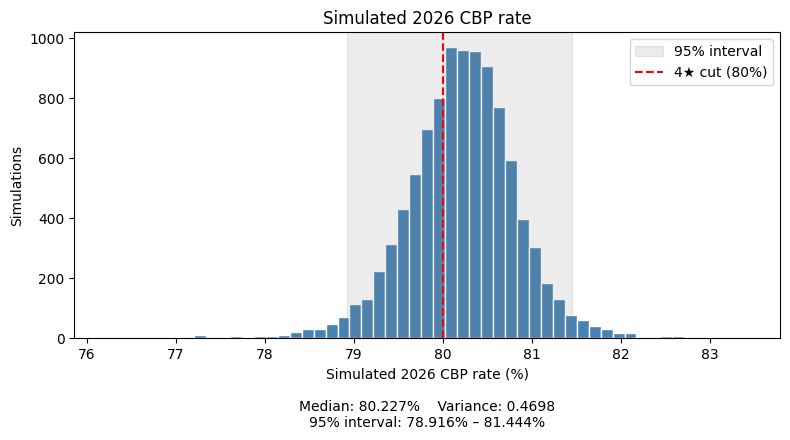

In [56]:
three_star = math.ceil(n_cbp * .75)
four_star = math.ceil(n_cbp * .80)
five_star = math.ceil(n_cbp * .86)

second, median, ninetyseventh = np.round(np.percentile(closed, [2.5, 50, 97.5])).astype(int)

lo, hi = np.percentile(rates, [2.5, 97.5])
lo_graph, hi_graph = np.percentile(rates, [0.1, 99.9])

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.hist(rates, bins=np.linspace(lo_graph, hi_graph, 60), color="steelblue", edgecolor="white")
ax.axvspan(lo, hi, color="gray", alpha=0.15, label="95% interval")
ax.axvline(80, color="red", linestyle="--", label="4★ cut (80%)")
ax.set_xlim(lo_graph, hi_graph)
ax.set_title("Simulated 2026 CBP rate")
ax.set_ylabel("Simulations")
ax.set_xlabel(f"Simulated 2026 CBP rate (%)\n\n"
              f"Median: {np.median(rates):.3f}%    Variance: {np.var(rates):.4f}\n"
              f"95% interval: {lo:.3f}% – {hi:.3f}%")
ax.legend()

plt.tight_layout()
plt.show()

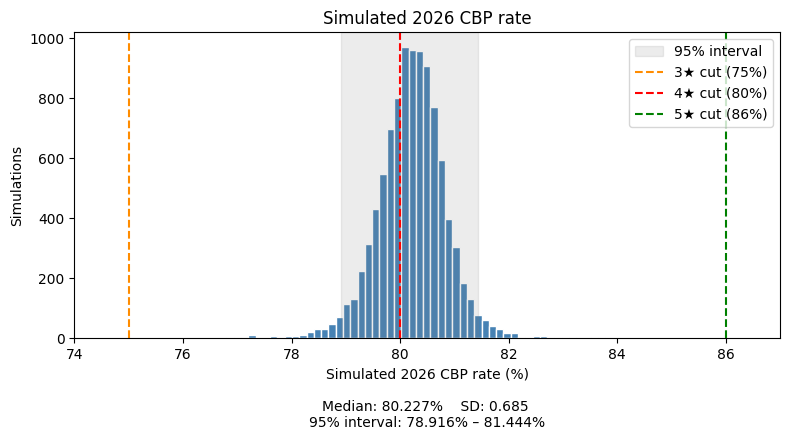

In [66]:
lo, hi = np.percentile(rates, [2.5, 97.5])
lo_graph, hi_graph = np.percentile(rates, [0.1, 99.9])

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.hist(rates, bins=np.linspace(lo_graph, hi_graph, 60), color="steelblue", edgecolor="white")
ax.axvspan(lo, hi, color="gray", alpha=0.15, label="95% interval")
ax.axvline(75, color="darkorange", linestyle="--", label="3★ cut (75%)")
ax.axvline(80, color="red", linestyle="--", label="4★ cut (80%)")
ax.axvline(86, color="green", linestyle="--", label="5★ cut (86%)")
ax.set_xlim(74, 87)
ax.set_title("Simulated 2026 CBP rate")
ax.set_ylabel("Simulations")
ax.set_xlabel(f"Simulated 2026 CBP rate (%)\n\n"
              f"Median: {np.median(rates):.3f}%    SD: {np.std(rates):.3f} \n"
              f"95% interval: {lo:.3f}% – {hi:.3f}%")
ax.legend()

plt.tight_layout()
plt.show()

In [62]:
mean, sd = np.mean(rates), np.std(rates)
five_star_runs = np.sort(rates[rates >= 86])

print(f"Mean: {mean:.3f}%    Variance: {np.var(rates):.4f}    SD: {sd:.3f}")
print(f"5 star cut point (86%) is {(86 - mean) / sd:.1f} SD above the mean")
print(f"Runs at or above 86%: {len(five_star_runs)} of {len(rates):,}")
for r in five_star_runs:
    print(f"    {r:.3f}%  ({(r - mean) / sd:.1f} SD above the mean)")

Mean: 80.212%    Variance: 0.4698    SD: 0.685
5 star cut point (86%) is 8.4 SD above the mean
Runs at or above 86%: 2 of 10,000
    88.064%  (11.5 SD above the mean)
    90.302%  (14.7 SD above the mean)


In [57]:
print(f"5 star: {100*(rates >= 86.0).mean():.2f}%")
print(f"4 star: {100*((rates >= 80.0) & (rates < 86.0)).mean():.2f}%")
print(f"3 star: {100*((rates >= 75.0) & (rates < 80.0)).mean():.2f}%")

5 star: 0.02%
4 star: 66.25%
3 star: 33.69%


In [58]:
print(f"2.5th percentile patients above 3 star cutpoint: {second - three_star}, {100 * max(three_star - second, 0) / (n_cbp - second):.1f}% uplift needed")
print(f"50th percentile patients above 3 star cutpoint: {median - three_star}, {100 * max(three_star - median, 0) / (n_cbp - median):.1f}% uplift needed")
print(f"97.5th percentile patients above 3 star cutpoint: {ninetyseventh - three_star}, {100 * max(three_star - ninetyseventh, 0) / (n_cbp - ninetyseventh):.1f}% uplift needed")
print()
print(f"2.5th percentile patients above 4 star cutpoint: {second - four_star}, {100 * max(four_star - second, 0) / (n_cbp - second):.1f}% uplift needed")
print(f"50th percentile patients above 4 star cutpoint: {median - four_star}, {100 * max(four_star - median, 0) / (n_cbp - median):.1f}% uplift needed")
print(f"97.5th percentile patients above 4 star cutpoint: {ninetyseventh - four_star}, {100 * max(four_star - ninetyseventh, 0) / (n_cbp - ninetyseventh):.1f}% uplift needed")
print()
print(f"2.5th percentile patients below 5 star cutpoint: {five_star - second}, {100 * max(five_star - second, 0) / (n_cbp - second):.1f}% uplift needed")
print(f"50th percentile patients below 5 star cutpoint: {five_star - median}, {100 * max(five_star - median, 0) / (n_cbp - median):.1f}% uplift needed")
print(f"97.5th percentile patients below 5 star cutpoint: {five_star - ninetyseventh}, {100 * max(five_star - ninetyseventh, 0) / (n_cbp - ninetyseventh):.1f}% uplift needed")
print()
print(f"2.5th percentile predicted open end of year: {n_cbp - second}")
print(f"50th percentile predicted open end of year: {n_cbp - median}")
print(f"97.5th percentile predicted open end of year: {n_cbp - ninetyseventh}")

2.5th percentile patients above 3 star cutpoint: 540, 0.0% uplift needed
50th percentile patients above 3 star cutpoint: 721, 0.0% uplift needed
97.5th percentile patients above 3 star cutpoint: 889, 0.0% uplift needed

2.5th percentile patients above 4 star cutpoint: -150, 5.2% uplift needed
50th percentile patients above 4 star cutpoint: 31, 0.0% uplift needed
97.5th percentile patients above 4 star cutpoint: 199, 0.0% uplift needed

2.5th percentile patients below 5 star cutpoint: 979, 33.6% uplift needed
50th percentile patients below 5 star cutpoint: 798, 29.2% uplift needed
97.5th percentile patients below 5 star cutpoint: 630, 24.6% uplift needed

2.5th percentile predicted open end of year: 2911
50th percentile predicted open end of year: 2730
97.5th percentile predicted open end of year: 2562


## Model Reliability

In [89]:
# Table Format

header_bg = "#1f3a5f"; header_fg = "#ffffff"
stripe_bg = "#eef2f8"; border = "#c9d4e4"
cell_bg = "#ffffff"; cell_fg = "#1a1a1a"

table_styles = [
    {"selector": "", "props": [("border-collapse", "collapse")]},
    {"selector": "caption", "props": [("caption-side", "top"), ("background-color", header_bg), ("color", header_fg),
                                      ("font-size", "16px"), ("font-weight", "bold"), ("text-align", "left"),
                                      ("padding", "10px 14px"), ("border-radius", "6px 6px 0 0")]},
    {"selector": "th", "props": [("background-color", header_bg), ("color", header_fg), ("font-weight", "bold"),
                                 ("padding", "8px 14px"), ("border", f"1px solid {border}")]},
    {"selector": "th.col_heading", "props": [("text-align", "center")]},
    {"selector": "th.index_name", "props": [("text-align", "right")]},
    {"selector": "th.row_heading", "props": [("text-align", "left")]},
    {"selector": "td", "props": [("background-color", cell_bg), ("color", cell_fg), ("text-align", "center"),
                                 ("padding", "8px 14px"), ("border", f"1px solid {border}")]},
    {"selector": "tbody tr:nth-child(even) td", "props": [("background-color", stripe_bg)]},
]

def style_table(df, title, row_formats=None, col_formats=None, hide_index=False, precision=1):
    styler = (df.style
                .format(precision=precision, thousands=",")
                .set_caption(title)
                .set_table_styles(table_styles))
    for row, fmt in (row_formats or {}).items():
        styler = styler.format(fmt, subset=pd.IndexSlice[[row], :])
    for col, fmt in (col_formats or {}).items():
        styler = styler.format(fmt, subset=[col])
    if hide_index:
        styler = styler.hide(axis="index")
    return styler

In [95]:
rates_by_year = cbp_pop[cbp_pop["year"].isin(prior_years)].groupby("year")[["closed_may", "closed_eoy"]].mean() * 100
rates_by_year["gain"] = rates_by_year["closed_eoy"] - rates_by_year["closed_may"]
bt["naive_pred"] = [rates_by_year.loc[y, "closed_may"] + rates_by_year.loc[rates_by_year.index < y, "gain"].mean()
                    for y in bt["test_year"]]
bt["naive_error"] = bt["naive_pred"] - bt["rate_actual"]
bt_members = cbp_pop[cbp_pop["year"].isin(bt["test_year"])].groupby("year").size().to_numpy()

backtest_tbl = pd.DataFrame({"Test Year": bt["test_year"],
                             "Trained On": bt["fit_years"],
                             "Actual (%)": bt["rate_actual"],
                             "Model (%)": bt["rate_pred"],
                             "Model Error (%\u00a0pts)": bt["rate_error"],
                             "Model Error (members)": (bt["rate_error"] / 100 * bt_members).round(),
                             "Naive (%)": bt["naive_pred"],
                             "Naive Error (%\u00a0pts)": bt["naive_error"]})

print(f"Mean absolute error: model {bt['rate_error'].abs().mean():.2f} pp, naive {bt['naive_error'].abs().mean():.2f} pp")
backtest_styled = style_table(backtest_tbl, "Forecast vs Actual Year End Rate", hide_index=True, precision=2,
                              col_formats={"Test Year": "{}",
                                            "Model Error (%\u00a0pts)": "{:+.2f}",
                                            "Model Error (members)": "{:+,.0f}",
                                            "Naive Error (%\u00a0pts)": "{:+.2f}"})
display(backtest_styled)

Mean absolute error: model 0.35 pp, naive 0.50 pp


Test Year,Trained On,Actual (%),Model (%),Model Error (% pts),Model Error (members),Naive (%),Naive Error (% pts)
2023,2022-2022,78.89,78.39,-0.50,-61,78.50,-0.39
2024,2022-2023,79.26,79.31,+0.05,+7,79.82,+0.56
2025,2022-2024,79.29,79.77,+0.49,+67,79.82,+0.54


In [97]:
dfi.export(backtest_styled, r"C:\Users\jacob\ma_quality\notebooks\charts\backtest.png",
           table_conversion="chrome", dpi=200)

In [96]:
metrics_tbl = pd.DataFrame({"Model": ["Closure", "Reversion"],
                            "Members": [len(valid_y), len(reopen_valid_y)],
                            "Predicted Events": [p_va.sum(), p_va_reopen.sum()],
                            "Actual Events": [valid_y.sum(), reopen_valid_y.sum()],
                            "AUC": [roc_auc_score(valid_y, p_va), roc_auc_score(reopen_valid_y, p_va_reopen)],
                            "Brier": [brier_score_loss(valid_y, p_va), brier_score_loss(reopen_valid_y, p_va_reopen)],
                            "Baseline Brier": [valid_y.mean() * (1 - valid_y.mean()),
                                               reopen_valid_y.mean() * (1 - reopen_valid_y.mean())]})
metrics_tbl["Brier Skill (%)"] = 100 * (1 - metrics_tbl["Brier"] / metrics_tbl["Baseline Brier"])

metrics_styled = style_table(metrics_tbl, "Validation Metrics", hide_index=True, precision=3,
                             col_formats={"Members": "{:,.0f}",
                                          "Predicted Events": "{:,.0f}",
                                          "Actual Events": "{:,.0f}",
                                          "Brier Skill (%)": "{:.1f}"})
display(metrics_styled)

Model,Members,Predicted Events,Actual Events,AUC,Brier,Baseline Brier,Brier Skill (%)
Closure,"7,741","5,109","5,043",0.770,0.156,0.227,31.1
Reversion,"5,979",143,144,0.933,0.019,0.024,18.2


In [98]:
dfi.export(metrics_styled, r"C:\Users\jacob\ma_quality\notebooks\charts\validation_metrics.png",
           table_conversion="chrome", dpi=200)

In [100]:
closure_cal = pd.DataFrame({"p": p_va, "y": valid_y.values})
closure_cal["decile"] = pd.qcut(closure_cal["p"], 10, labels=range(1, 11))
cal_tbl = closure_cal.groupby("decile", observed=True).agg(members=("y", "size"), predicted=("p", "mean"), actual=("y", "mean"))
cal_tbl[["predicted", "actual"]] *= 100
cal_tbl["diff (% pts)"] = cal_tbl["predicted"] - cal_tbl["actual"]
cal_tbl.columns = ["Members", "Predicted (%)", "Actual (%)", "Difference (% pts)"]

cal_styled = style_table(cal_tbl.reset_index().rename(columns={"decile": "Decile"}),
                         "Closure Model Calibration by Decile", hide_index=True,
                         col_formats={"Members": "{:,.0f}",
                                      "Difference (% pts)": "{:+.1f}"})
display(cal_styled)

Decile,Members,Predicted (%),Actual (%),Difference (% pts)
1,775,4.2,3.0,+1.2
2,774,28.4,26.2,+2.2
3,774,71.8,69.5,+2.3
4,777,73.6,71.3,+2.3
5,775,75.7,75.2,+0.5
6,770,77.6,74.5,+3.1
7,778,79.6,82.8,-3.2
8,770,81.3,83.2,-1.9
9,776,83.1,84.4,-1.4
10,772,84.9,81.3,+3.6


In [101]:
dfi.export(cal_styled, r"C:\Users\jacob\ma_quality\notebooks\charts\calibration.png",
           table_conversion="chrome", dpi=200)

In [ ]:
con.close()